# Practical 3 report: QSAR bioconcentration challenge

**Student:** Yevhenii Zasko  
**Practical:** 3 - Regression Zoo and classification

In [71]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer  # noqa: F401, enables IterativeImputer
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import (
    HuberRegressor,
    LinearRegression,
    LogisticRegression,
    RANSACRegressor,
    Ridge,
    TheilSenRegressor,
)
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler

RANDOM_STATE = 111026

## EDA

In [72]:
train = pd.read_csv("QSAR_challenge_train_80pct.csv")
test = pd.read_csv("QSAR_challenge_test_20pct_NO_TARGETS.csv")

feature_cols = [c for c in test.columns if c != "sample_id"]

X = train[feature_cols]
y_reg = train["regression_target"]
y_cls = train["classification_target"]
X_hidden = test[feature_cols]

print("Train:", train.shape, "Hidden test:", test.shape)
print("Features:", feature_cols)
train

Train: (623, 12) Hidden test: (156, 10)
Features: ['nHM', 'piPC09', 'PCD', 'X2Av', 'MLOGP', 'ON1V', 'N-072', 'B02[C-N]', 'F04[C-O]']


,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
0,2234-13-1,8.0,7.157,2.41,0.21,6.55,0.97,0.0,0.0,0.0,2.58,3
1,108-42-9,1.0,0.000,1.23,0.20,2.13,0.68,0.0,1.0,NaN,0.33,3
2,106-43-4,1.0,0.000,1.23,0.22,3.21,0.84,0.0,0.0,0.0,1.80,1
3,108-87-2,0.0,0.000,0.00,0.34,3.48,1.67,0.0,0.0,0.0,2.32,1
4,101-81-5,0.0,5.614,2.21,0.19,4.15,1.47,0.0,0.0,0.0,2.97,1
...,...,...,...,...,...,...,...,...,...,...,...,...
618,17700-09-3,3.0,0.000,1.49,0.18,3.70,0.69,0.0,1.0,4.0,2.20,1
619,5915-41-3,1.0,3.056,1.21,0.21,2.89,1.90,0.0,1.0,0.0,0.84,3
620,39515-41-8/64257-84-7,0.0,6.428,2.25,0.19,3.56,2.92,0.0,1.0,15.0,3.04,3
621,26644-46-2,6.0,4.043,0.16,0.29,1.40,1.86,2.0,1.0,2.0,0.00,3


| Feature | Description | Type |
|---|---|---|
| `nHM` | Number of heavy atoms (halogens and similar atoms such as Cl, Br, I) | count (0–12) |
| `piPC09` | Molecular multiple path count of order 9 (log-transformed); size and complexity | continuous ≥ 0 |
| `PCD` | Difference between multiple path count and path count; reflects double, triple and aromatic bonds | continuous ≥ 0 |
| `X2Av` | Average valence connectivity index of order 2; branching and heteroatoms | continuous |
| `MLOGP` | Moriguchi octanol–water partition coefficient (logP); lipophilicity | continuous, can be negative |
| `ON1V` | Overall modified Zagreb index of order 1 by valence vertex degrees; size and branching | continuous > 0 |
| `N-072` | Atom-centred fragment count: RCO-N< / >N-X=X (amide-type nitrogen) | count (0–3) |
| `B02[C-N]` | Presence/absence of a C–N pair at topological distance 2 | binary (0/1) |
| `F04[C-O]` | Frequency of C–O pairs at topological distance 4 | count (0–20) |

In [73]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sample_id              623 non-null    str    
 1   nHM                    612 non-null    float64
 2   piPC09                 610 non-null    float64
 3   PCD                    616 non-null    float64
 4   X2Av                   611 non-null    float64
 5   MLOGP                  610 non-null    float64
 6   ON1V                   609 non-null    float64
 7   N-072                  604 non-null    float64
 8   B02[C-N]               616 non-null    float64
 9   F04[C-O]               607 non-null    float64
 10  regression_target      623 non-null    float64
 11  classification_target  623 non-null    int64  
dtypes: float64(10), int64(1), str(1)
memory usage: 58.5 KB


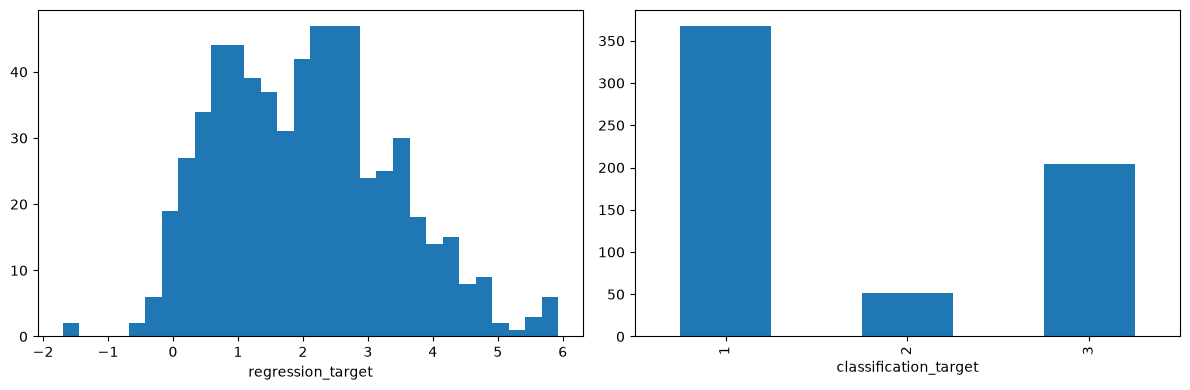

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_reg, bins=30)
axes[0].set_xlabel("regression_target")
y_cls.value_counts().sort_index().plot.bar(ax=axes[1])
plt.tight_layout()
plt.show()

In [75]:
na_df = pd.DataFrame({
    "train_na": train[feature_cols].isna().sum(),
    "train_pct": (train[feature_cols].isna().mean() * 100).round(1),
    "test_na": test[feature_cols].isna().sum(),
    "test_pct": (test[feature_cols].isna().mean() * 100).round(1),
})
print("Target NA:", y_reg.isna().sum(), y_cls.isna().sum())
na_df

Target NA: 0 0


,train_na,train_pct,test_na,test_pct
nHM,11,1.8,3,1.9
piPC09,13,2.1,4,2.6
PCD,7,1.1,5,3.2
X2Av,12,1.9,3,1.9
MLOGP,13,2.1,2,1.3
ON1V,14,2.2,2,1.3
N-072,19,3.0,3,1.9
B02[C-N],7,1.1,3,1.9
F04[C-O],16,2.6,3,1.9


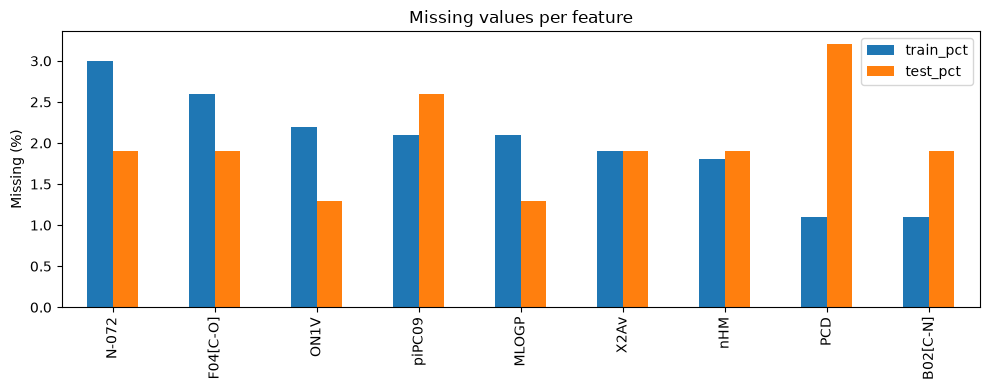

In [76]:
na_df[["train_pct", "test_pct"]].sort_values("train_pct", ascending=False).plot.bar(figsize=(10, 4))
plt.ylabel("Missing (%)")
plt.title("Missing values per feature")
plt.tight_layout()
plt.show()

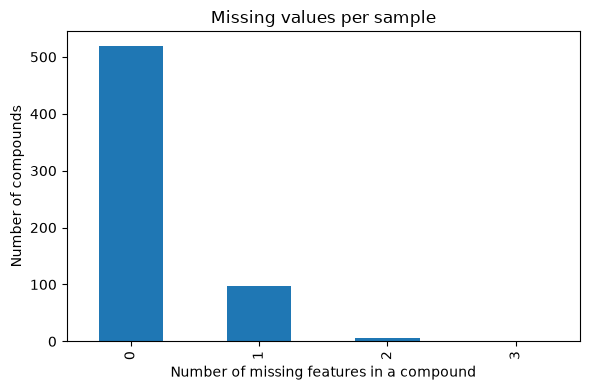

In [77]:
na_per_row = train[feature_cols].isna().sum(axis=1)

na_per_row.value_counts().sort_index().plot.bar(figsize=(6, 4))
plt.xlabel("Number of missing features in a compound")
plt.ylabel("Number of compounds")
plt.title("Missing values per sample")
plt.tight_layout()
plt.show()


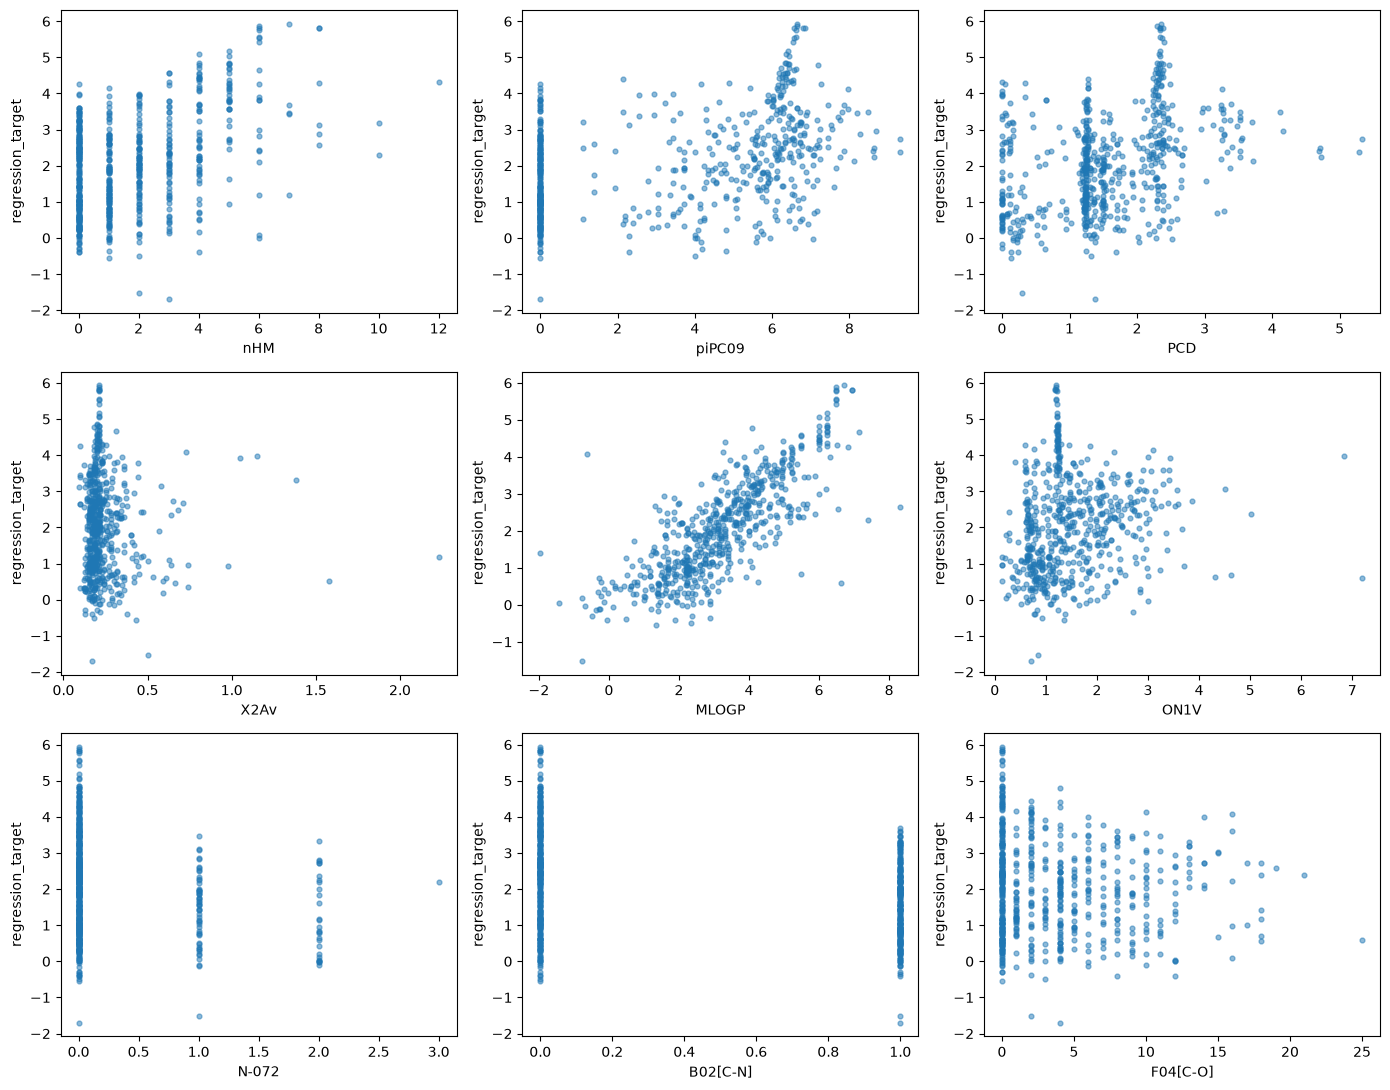

In [78]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), feature_cols):
    ax.scatter(train[col], train["regression_target"], alpha=0.5, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel("regression_target")
plt.tight_layout()
plt.show()

only for mlogp relation is kinda linear

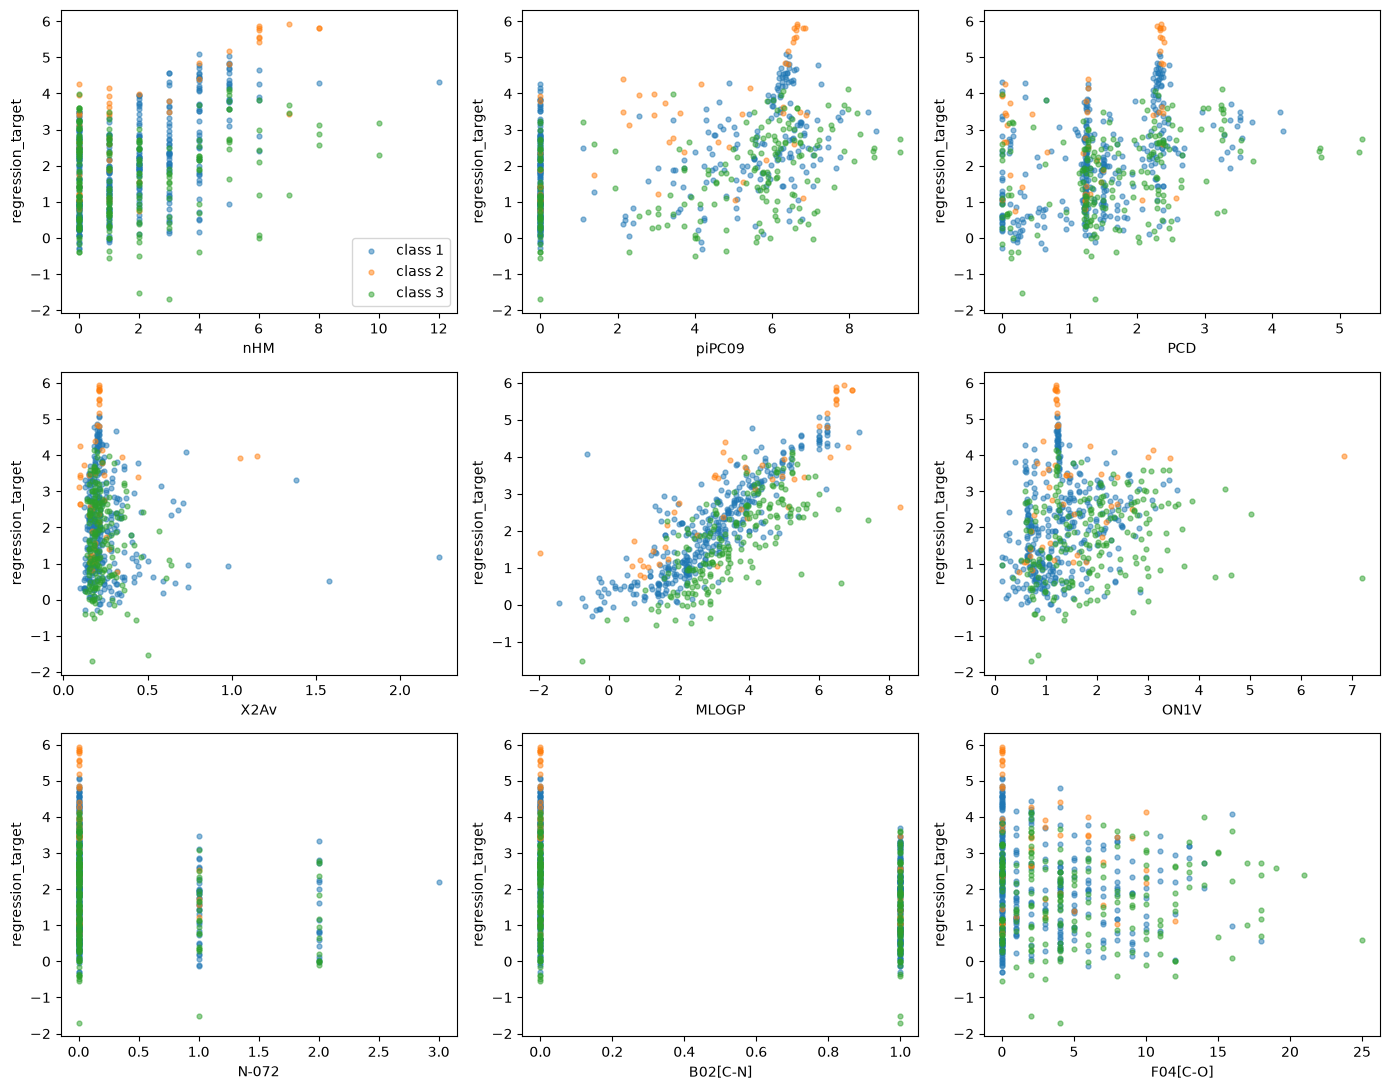

In [79]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.ravel(), feature_cols):
    for cls, group in train.groupby("classification_target"):
        ax.scatter(group[col], group["regression_target"], alpha=0.5, s=12, label=f"class {cls}")
    ax.set_xlabel(col)
    ax.set_ylabel("regression_target")
axes[0, 0].legend()
plt.tight_layout()
plt.show()


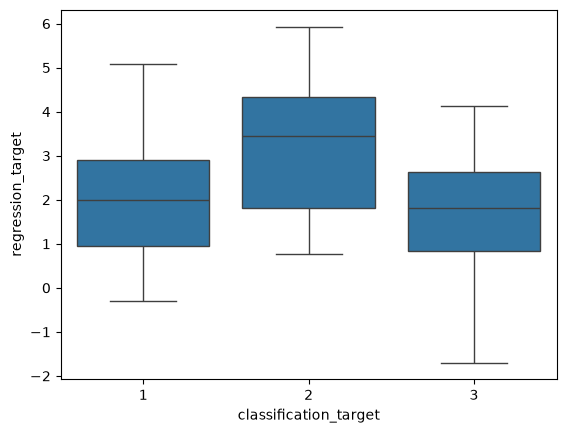

In [80]:
sns.boxplot(data=train, x="classification_target", y="regression_target")
plt.show()

In [81]:
corr = train[feature_cols + ["regression_target"]].corr(method="spearman")
corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target
nHM,1.00,0.06,-0.00,0.46,0.30,-0.26,-0.06,-0.20,-0.06,0.36
piPC09,0.06,1.00,0.78,-0.32,0.52,0.57,0.12,0.00,0.24,0.45
PCD,-0.00,0.78,1.00,-0.56,0.47,0.25,-0.02,0.12,0.19,0.38
X2Av,0.46,-0.32,-0.56,1.00,-0.03,-0.05,-0.06,-0.32,-0.21,0.04
MLOGP,0.30,0.52,0.47,-0.03,1.00,0.27,-0.22,-0.37,-0.14,0.79
ON1V,-0.26,0.57,0.25,-0.05,0.27,1.00,0.29,0.14,0.46,0.23
N-072,-0.06,0.12,-0.02,-0.06,-0.22,0.29,1.00,0.41,0.28,-0.20
B02[C-N],-0.20,0.00,0.12,-0.32,-0.37,0.14,0.41,1.00,0.26,-0.32
F04[C-O],-0.06,0.24,0.19,-0.21,-0.14,0.46,0.28,0.26,1.00,-0.10
regression_target,0.36,0.45,0.38,0.04,0.79,0.23,-0.20,-0.32,-0.10,1.00


high correlation between regression target and mlogp is high, also mb worth flagging the pcd/pipc09 relation

In [ ]:
corr = train[feature_cols + ["regression_target"]].corr(method="pearson")
corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target
nHM,1.00,0.10,-0.04,0.21,0.40,-0.23,-0.08,-0.26,-0.13,0.46
piPC09,0.10,1.00,0.72,-0.25,0.50,0.47,0.16,0.03,0.29,0.44
PCD,-0.04,0.72,1.00,-0.43,0.45,0.16,-0.04,0.10,0.11,0.37
X2Av,0.21,-0.25,-0.43,1.00,-0.11,0.03,-0.06,-0.22,-0.10,-0.04
MLOGP,0.40,0.50,0.45,-0.11,1.00,0.25,-0.22,-0.36,-0.09,0.79
ON1V,-0.23,0.47,0.16,0.03,0.25,1.00,0.22,0.12,0.55,0.15
N-072,-0.08,0.16,-0.04,-0.06,-0.22,0.22,1.00,0.39,0.19,-0.20
B02[C-N],-0.26,0.03,0.10,-0.22,-0.36,0.12,0.39,1.00,0.21,-0.34
F04[C-O],-0.13,0.29,0.11,-0.10,-0.09,0.55,0.19,0.21,1.00,-0.10
regression_target,0.46,0.44,0.37,-0.04,0.79,0.15,-0.20,-0.34,-0.10,1.00


similar to spearman, some form of linear relation is present

In [83]:
print("Exact duplicate rows:", train.duplicated().sum())
print("Duplicate sample_id:", train["sample_id"].duplicated().sum())

Exact duplicate rows: 0
Duplicate sample_id: 0


In [84]:
dup = train[train.duplicated(subset=feature_cols, keep=False)].sort_values(feature_cols)
print("Rows in feature-duplicate groups:", len(dup))
dup[["sample_id"] + feature_cols + ["regression_target", "classification_target"]]

Rows in feature-duplicate groups: 31


,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
113,105-05-5,0.0,0.000,1.22,0.21,3.56,1.81,0.0,0.0,0.0,2.71,1
353,141-93-5,0.0,0.000,1.22,0.21,3.56,1.81,0.0,0.0,0.0,2.77,1
152,462-08-8,0.0,0.000,1.23,0.16,-0.15,0.61,0.0,1.0,0.0,0.07,1
496,504-24-5,0.0,0.000,1.23,0.16,-0.15,0.61,0.0,1.0,0.0,0.44,1
221,95-64-7,0.0,0.000,1.24,0.20,2.19,1.09,0.0,1.0,0.0,0.80,1
544,95-78-3,0.0,0.000,1.24,0.20,2.19,1.09,0.0,1.0,0.0,0.54,1
151,2243-62-1,0.0,6.423,2.39,0.16,2.02,1.13,0.0,1.0,0.0,0.46,1
586,479-27-6,0.0,6.423,2.39,0.16,2.02,1.13,0.0,1.0,0.0,0.78,1
120,108-43-0,1.0,0.000,1.23,0.19,2.13,0.64,0.0,0.0,1.0,1.14,1
297,106-48-9,1.0,0.000,1.23,0.19,2.13,0.64,0.0,0.0,1.0,1.42,1


same features might be different classification targets and different regression target 🤔

## Test/train split

In [85]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X, y_cls))

## Regression

In [86]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}
    


In [87]:
def evaluate_regression(name, make_model, imputer, cols=feature_cols):
    res = []
    for train_idx, val_idx in folds:
        X_tr, X_val = X.iloc[train_idx][cols], X.iloc[val_idx][cols]
        y_tr, y_val = y_reg.iloc[train_idx], y_reg.iloc[val_idx]

        model = make_model(clone(imputer))
        model.fit(X_tr, y_tr)

        res.append({"model": name, "split": "train", **regression_metrics(y_tr, model.predict(X_tr))})
        res.append({"model": name, "split": "validation", **regression_metrics(y_val, model.predict(X_val))})
    return pd.DataFrame(res).groupby(["model", "split"]).mean().reset_index().to_dict("records")

In [88]:
def linear(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", LinearRegression())])
    
def spline_ridge(imputer, n_knots=5, degree=3, alpha=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("spline", SplineTransformer(n_knots=n_knots, degree=degree)),
        ("model", Ridge(alpha=alpha))])
    
def huber(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", HuberRegressor(max_iter=2000))])

def ransac(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", RANSACRegressor(random_state=RANDOM_STATE))])

def theilsen(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", TheilSenRegressor(random_state=RANDOM_STATE))])
    
def polynomial(imputer, degree=2, alpha=10.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", Ridge(alpha=alpha))])
    
def gp(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=np.ones(len(feature_cols))) + WhiteKernel(1.0),
            normalize_y=True, random_state=RANDOM_STATE))])

In [89]:
imputers = {
    "median": SimpleImputer(strategy="median"),
    "knn": KNNImputer(n_neighbors=5),
    "iterative": IterativeImputer(random_state=RANDOM_STATE),
}

In [90]:
reg_results = []
for imp_name, imputer in imputers.items():
    reg_results += evaluate_regression(f"Simple (MLOGP) | {imp_name}", linear, imputer, ["MLOGP"])
    reg_results += evaluate_regression(f"Multiple (all) | {imp_name}", linear, imputer)
    reg_results += evaluate_regression(f"Spline + Ridge | {imp_name}", lambda imp: spline_ridge(imp, 5, 3, 1), imputer)
    reg_results += evaluate_regression(f"Huber | {imp_name}", huber, imputer)
    reg_results += evaluate_regression(f"RANSAC | {imp_name}", ransac, imputer)
    reg_results += evaluate_regression(f"Theil-Sen | {imp_name}", theilsen, imputer)
    reg_results += evaluate_regression(f"Polynomial (d=2) | {imp_name}", lambda imp: polynomial(imp, 2, 1), imputer)
    reg_results += evaluate_regression(f"Polynomial (d=3) | {imp_name}", lambda imp: polynomial(imp, 3, 1), imputer)
    reg_results += evaluate_regression(f"Gaussian Process | {imp_name}", gp, imputer)

In [91]:
spline_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("impute", SimpleImputer(strategy="median")),
    ("spline", SplineTransformer()),
    ("model", Ridge())])

param_grid = {
    "impute": [SimpleImputer(strategy="median"), KNNImputer(n_neighbors=5), IterativeImputer(random_state=RANDOM_STATE)],
    "spline__n_knots": [3, 5, 7, 10],
    "spline__degree": [1, 2, 3],
    "spline__knots": ["uniform", "quantile"],
    "spline__extrapolation": ["constant", "linear"],
    "model__alpha": [0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
}

search = GridSearchCV(spline_pipe, param_grid, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X, y_reg)

best = search.best_params_
print("Best params:", best)

reg_results += evaluate_regression(
    "Spline (tuned)",
    lambda imp: Pipeline([
        ("scale", StandardScaler()),
        ("impute", imp),
        ("spline", SplineTransformer(
            n_knots=best["spline__n_knots"],
            degree=best["spline__degree"],
            knots=best["spline__knots"],
            extrapolation=best["spline__extrapolation"])),
        ("model", Ridge(alpha=best["model__alpha"]))]),
    best["impute"])

Best params: {'impute': IterativeImputer(random_state=111026), 'model__alpha': 0.5, 'spline__degree': 2, 'spline__extrapolation': 'constant', 'spline__knots': 'uniform', 'spline__n_knots': 7}


In [92]:
ensemble = [
    lambda imp: spline_ridge(imp, 7, 2, 0.5),
    lambda imp: polynomial(imp, 2, 30.0),
    gp,
]

res = []
for train_idx, val_idx in folds:
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y_reg.iloc[train_idx], y_reg.iloc[val_idx]
    models = [make(clone(imputers["iterative"])).fit(X_tr, y_tr) for make in ensemble]
    res.append({"model": "Ensemble (spline+poly2+GP)", "split": "train", **regression_metrics(y_tr, np.mean([m.predict(X_tr) for m in models], axis=0))})
    res.append({"model": "Ensemble (spline+poly2+GP)", "split": "validation", **regression_metrics(y_val, np.mean([m.predict(X_val) for m in models], axis=0))})

reg_results += pd.DataFrame(res).groupby(["model", "split"]).mean().reset_index().to_dict("records")

In [93]:
reg_df = pd.DataFrame(reg_results)
reg_df[reg_df["split"] == "validation"].sort_values("RMSE").round(3)

,model,split,MAE,MSE,RMSE,R2
57,Ensemble (spline+poly2+GP),validation,0.553,0.532,0.727,0.694
55,Spline (tuned),validation,0.580,0.576,0.757,0.669
53,Gaussian Process | iterative,validation,0.569,0.577,0.758,0.667
41,Spline + Ridge | iterative,validation,0.585,0.582,0.762,0.665
23,Spline + Ridge | knn,validation,0.587,0.590,0.766,0.662
5,Spline + Ridge | median,validation,0.588,0.593,0.769,0.659
35,Gaussian Process | knn,validation,0.572,0.595,0.769,0.659
17,Gaussian Process | median,validation,0.576,0.600,0.773,0.654
49,Polynomial (d=2) | iterative,validation,0.606,0.658,0.808,0.622
39,Multiple (all) | iterative,validation,0.623,0.657,0.808,0.623


## Classification

Explained variance: [0.283 0.228 0.145]


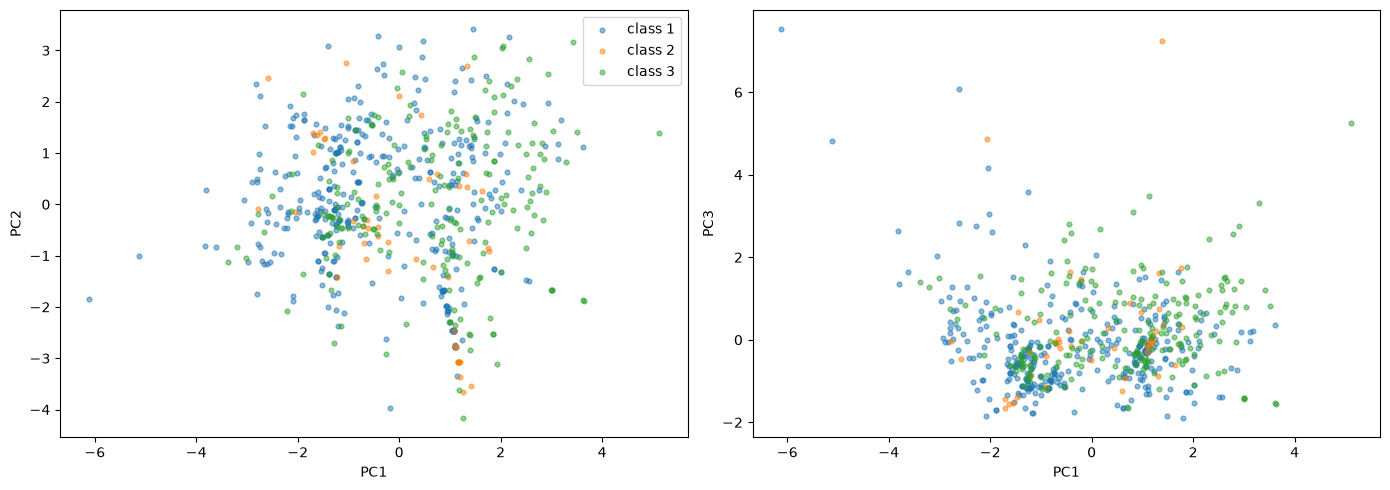

In [94]:
pca_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("impute", SimpleImputer(strategy="median")),
    ("pca", PCA(n_components=3))])
coords = pca_pipe.fit_transform(X)

print("Explained variance:", pca_pipe.named_steps["pca"].explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    for cls in sorted(y_cls.unique()):
        m = (y_cls == cls).values
        ax.scatter(coords[m, a], coords[m, b], alpha=0.5, s=12, label=f"class {cls}")
    ax.set_xlabel(f"PC{a + 1}")
    ax.set_ylabel(f"PC{b + 1}")
axes[0].legend()
plt.tight_layout()
plt.show()

In [95]:
cls_dummies = pd.get_dummies(y_cls, prefix="class").astype(float)
cls_corr = pd.DataFrame({c: X.corrwith(cls_dummies[c], method="spearman") for c in cls_dummies})
cls_corr.style.background_gradient(cmap="coolwarm", vmin=-0.5, vmax=0.5).format("{:.2f}")

,class_1,class_2,class_3
nHM,0.00,0.03,-0.02
piPC09,-0.21,0.06,0.18
PCD,-0.10,-0.04,0.12
X2Av,0.02,-0.05,0.01
MLOGP,-0.20,0.10,0.15
ON1V,-0.28,-0.01,0.30
N-072,-0.01,-0.05,0.04
B02[C-N],0.12,-0.09,-0.07
F04[C-O],-0.24,-0.04,0.27


In [96]:
def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - tp - fp - fn
    return {
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "specificity": np.mean(tn / (tn + fp)),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0)}

In [97]:
def evaluate_classification(name, make_model, imputer, cols=feature_cols):
    res = []
    for train_idx, val_idx in folds:
        X_tr, X_val = X.iloc[train_idx][cols], X.iloc[val_idx][cols]
        y_tr, y_val = y_cls.iloc[train_idx], y_cls.iloc[val_idx]

        model = make_model(clone(imputer))
        model.fit(X_tr, y_tr)

        res.append({"model": name, "split": "train", **classification_metrics(y_tr, model.predict(X_tr))})
        res.append({"model": name, "split": "validation", **classification_metrics(y_val, model.predict(X_val))})
    return pd.DataFrame(res).groupby(["model", "split"]).mean().reset_index().to_dict("records")

In [98]:
def logistic(imputer):
    return Pipeline([
        ("impute", imputer),
        ("model", LogisticRegression(max_iter=3000))])

def logistic_balanced(imputer):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    
def logistic_poly(imputer, degree=2, C=0.1):
    return Pipeline([
        ("scale", StandardScaler()),
        ("impute", imputer),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", LogisticRegression(max_iter=5000, class_weight="balanced", C=C))])
    
def spline(imputer):
    return Pipeline([
    ("scale", StandardScaler()),
    ("impute", imputer),
    ("spline", SplineTransformer()),
    ("model", LogisticRegression(max_iter=5000))])

In [99]:
cls_results = []
for imp_name, imputer in imputers.items():
    cls_results += evaluate_classification(f"Logistic | {imp_name}", logistic, imputer)
    cls_results += evaluate_classification(f"Logistic balanced | {imp_name}", logistic_balanced, imputer)   
    cls_results += evaluate_classification(f"Logistic poly d=2 | {imp_name}", lambda imp: logistic_poly(imp, 2, 0.1), imputer)
    cls_results += evaluate_classification(f"Logistic poly d=3 | {imp_name}", lambda imp: logistic_poly(imp, 3, 0.1), imputer)
    cls_results += evaluate_classification(f"Spline | {imp_name}", lambda imp: logistic_poly(imp, 3, 0.1), imputer)

In [100]:
cls_df = pd.DataFrame(cls_results)
cls_df[cls_df["split"] == "validation"].sort_values("f1", ascending=False).round(3)

,model,split,precision,recall,specificity,f1
25,Logistic poly d=2 | iterative,validation,0.508,0.564,0.770,0.513
5,Logistic poly d=2 | median,validation,0.506,0.564,0.771,0.510
17,Logistic poly d=3 | knn,validation,0.498,0.541,0.761,0.508
19,Spline | knn,validation,0.498,0.541,0.761,0.508
15,Logistic poly d=2 | knn,validation,0.503,0.557,0.766,0.507
7,Logistic poly d=3 | median,validation,0.495,0.538,0.761,0.504
9,Spline | median,validation,0.495,0.538,0.761,0.504
27,Logistic poly d=3 | iterative,validation,0.493,0.530,0.757,0.500
29,Spline | iterative,validation,0.493,0.530,0.757,0.500
21,Logistic | iterative,validation,0.584,0.454,0.753,0.459


In [101]:
cls_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("impute", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", LogisticRegression(max_iter=5000))])

cls_grid = {
    "impute": [SimpleImputer(strategy="median"), KNNImputer(n_neighbors=5), IterativeImputer(random_state=RANDOM_STATE)],
    "poly__degree": [1, 2, 3, 4],
    "poly__interaction_only": [False, True],
    "model__C": [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}

cls_search = GridSearchCV(cls_pipe, cls_grid, cv=folds, scoring="f1_macro", n_jobs=-1)
cls_search.fit(X, y_cls)
best_cls = cls_search.best_params_
print(best_cls)

cls_results += evaluate_classification(
    "Logistic (tuned)",
    lambda imp: Pipeline([
        ("scale", StandardScaler()),
        ("impute", imp),
        ("poly", PolynomialFeatures(degree=best_cls["poly__degree"], interaction_only=best_cls["poly__interaction_only"], include_bias=False)),
        ("model", LogisticRegression(
            max_iter=5000,
            C=best_cls["model__C"],
            class_weight=best_cls["model__class_weight"]))]),
    best_cls["impute"])

{'impute': SimpleImputer(strategy='median'), 'model__C': 0.1, 'model__class_weight': None, 'poly__degree': 3, 'poly__interaction_only': False}


In [102]:
cls_df = pd.DataFrame(cls_results)
cls_df[cls_df["split"] == "validation"].sort_values("f1", ascending=False).round(3)

,model,split,precision,recall,specificity,f1
31,Logistic (tuned),validation,0.711,0.558,0.787,0.589
25,Logistic poly d=2 | iterative,validation,0.508,0.564,0.770,0.513
5,Logistic poly d=2 | median,validation,0.506,0.564,0.771,0.510
17,Logistic poly d=3 | knn,validation,0.498,0.541,0.761,0.508
19,Spline | knn,validation,0.498,0.541,0.761,0.508
15,Logistic poly d=2 | knn,validation,0.503,0.557,0.766,0.507
7,Logistic poly d=3 | median,validation,0.495,0.538,0.761,0.504
9,Spline | median,validation,0.495,0.538,0.761,0.504
27,Logistic poly d=3 | iterative,validation,0.493,0.530,0.757,0.500
29,Spline | iterative,validation,0.493,0.530,0.757,0.500


In [103]:
spline_cls_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("impute", SimpleImputer(strategy="median")),
    ("spline", SplineTransformer()),
    ("model", LogisticRegression(max_iter=5000))])

spline_cls_grid = {
    "impute": [SimpleImputer(strategy="median"), KNNImputer(n_neighbors=5), IterativeImputer(random_state=RANDOM_STATE)],
    "spline__n_knots": [3, 5, 7, 10],
    "spline__degree": [1, 2, 3],
    "spline__knots": ["uniform", "quantile"],
    "model__C": [0.03, 0.1, 0.3, 1.0, 3.0],
    "model__class_weight": [None, "balanced"],
}

spline_cls_search = GridSearchCV(spline_cls_pipe, spline_cls_grid, cv=folds, scoring="f1_macro", n_jobs=-1)
spline_cls_search.fit(X, y_cls)
print(spline_cls_search.best_score_, spline_cls_search.best_params_)

best_spline_cls = spline_cls_search.best_params_

cls_results += evaluate_classification(
    "Spline logistic (tuned)",
    lambda imp: Pipeline([
        ("scale", StandardScaler()),
        ("impute", imp),
        ("spline", SplineTransformer(n_knots=best_spline_cls["spline__n_knots"], degree=best_spline_cls["spline__degree"], knots=best_spline_cls["spline__knots"])),
        ("model", LogisticRegression(
            max_iter=5000,
            C=best_spline_cls["model__C"],
            class_weight=best_spline_cls["model__class_weight"]))]),
    best_spline_cls["impute"])

0.5905619479342276 {'impute': KNNImputer(), 'model__C': 3.0, 'model__class_weight': None, 'spline__degree': 3, 'spline__knots': 'uniform', 'spline__n_knots': 10}


In [112]:
cls_df = pd.DataFrame(cls_results)
cls_df[cls_df["split"] == "validation"].sort_values("f1", ascending=False).round(3)

,model,split,precision,recall,specificity,f1
39,Spline logistic | drop ['N-072'],validation,0.694,0.568,0.792,0.593
33,Spline logistic (tuned),validation,0.688,0.567,0.786,0.591
31,Logistic (tuned),validation,0.711,0.558,0.787,0.589
37,Spline logistic | drop ['X2Av'],validation,0.599,0.520,0.776,0.537
35,Spline logistic | drop ['nHM'],validation,0.621,0.508,0.766,0.524
25,Logistic poly d=2 | iterative,validation,0.508,0.564,0.770,0.513
5,Logistic poly d=2 | median,validation,0.506,0.564,0.771,0.510
17,Logistic poly d=3 | knn,validation,0.498,0.541,0.761,0.508
19,Spline | knn,validation,0.498,0.541,0.761,0.508
15,Logistic poly d=2 | knn,validation,0.503,0.557,0.766,0.507


In [104]:
drop_sets = [["nHM"], ["X2Av"], ["N-072"], ["nHM", "X2Av", "N-072"]]

for drop in drop_sets:
    cols = [c for c in feature_cols if c not in drop]
    cls_results += evaluate_classification(
        f"Spline logistic | drop {drop}",
        lambda imp: clone(spline_cls_search.best_estimator_),
        best_spline_cls["impute"],
        cols=cols)

cls_df = pd.DataFrame(cls_results)
cls_df[cls_df["split"] == "validation"].sort_values("f1", ascending=False).round(3)

,model,split,precision,recall,specificity,f1
39,Spline logistic | drop ['N-072'],validation,0.694,0.568,0.792,0.593
33,Spline logistic (tuned),validation,0.688,0.567,0.786,0.591
31,Logistic (tuned),validation,0.711,0.558,0.787,0.589
37,Spline logistic | drop ['X2Av'],validation,0.599,0.520,0.776,0.537
35,Spline logistic | drop ['nHM'],validation,0.621,0.508,0.766,0.524
25,Logistic poly d=2 | iterative,validation,0.508,0.564,0.770,0.513
5,Logistic poly d=2 | median,validation,0.506,0.564,0.771,0.510
17,Logistic poly d=3 | knn,validation,0.498,0.541,0.761,0.508
19,Spline | knn,validation,0.498,0.541,0.761,0.508
15,Logistic poly d=2 | knn,validation,0.503,0.557,0.766,0.507


In [106]:
models = [spline_cls_search.best_estimator_]

proba = np.mean([m.predict_proba(X_hidden) for m in models], axis=0)
cls_pred = models[0].classes_[proba.argmax(axis=1)]

In [110]:
X, X_hidden = train[feature_cols], test[feature_cols]
cols_8 = [c for c in feature_cols if c != "N-072"]

reg_search_8 = GridSearchCV(spline_pipe, param_grid, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
reg_search_8.fit(X[cols_8], y_reg)
print("reg:", -reg_search_8.best_score_, "vs", -search.best_score_)

cls_search_8 = GridSearchCV(spline_cls_pipe, spline_cls_grid, cv=folds, scoring="f1_macro", n_jobs=-1)
cls_search_8.fit(X[cols_8], y_cls)
print("cls:", cls_search_8.best_score_, "vs", spline_cls_search.best_score_)

reg: 0.7539340091007846 vs 0.7573587198135197
cls: 0.5926121984414704 vs 0.5905619479342276


In [111]:
final_reg_models = [make(clone(imputers["iterative"])).fit(X, y_reg) for make in ensemble]
final_cls = cls_search_8.best_estimator_

submission = pd.DataFrame({
    "sample_id": test["sample_id"],
    "regression_prediction": np.mean([m.predict(X_hidden) for m in final_reg_models], axis=0),
    "classification_prediction": final_cls.predict(X_hidden[cols_8]),
})

display(submission.head())
print(submission.shape, submission.isna().sum().sum())
submission.to_csv("submission_yevhenii_zasko7.csv", index=False)

,sample_id,regression_prediction,classification_prediction
0,78-79-5,0.882960,1
1,16606-02-3,3.987644,1
2,111-44-4,0.788503,1
3,107-05-1,0.656757,1
4,555-03-3,0.735029,1


(156, 3) 0
